# AutoAccel: Conventional vs. Karatsuba Multipliers

**Architecture comparison using parameterized SystemVerilog, open-source simulation, synthesis statistics, and formal equivalence.**

AutoAccel asks how the generic logic-cell count of two unsigned multiplier architectures changes as operand width grows. The notebook reads the audited CSVs and project evidence shipped with it; it does not rerun synthesis or overwrite result files.

> **Evidence boundary:** counts are generic Yosys cells, not physical area, power, or timing. N=8 full-output equivalence passed. N=16 full-output equivalence is unresolved after recorded timeouts.


## Research question and objectives

For each supported operand width, which implementation has fewer cells under the repository's fixed Yosys flow? The comparison covers a conventional shift-and-add multiplier and a Karatsuba multiplier. It reports the small-width cost of Karatsuba's extra decomposition logic alongside its measured counts at larger widths.

The experiment is an architecture comparison at selected widths, not a claim of universal crossover behavior or a physical implementation result.


## Architecture background

A conventional unsigned multiplier forms shifted partial products and adds them. The Karatsuba identity splits each operand into high and low halves and combines three half-width products, rather than four, with additions and subtractions to recover the cross term. Recursively applied, this can reduce the asymptotic number of single-bit products; at small widths, decomposition and recombination overhead can outweigh that benefit.

These operation-count arguments describe the algorithm. The measurements below instead count generic cells in the synthesized RTL netlist. The mapping flow, RTL structure, and tool version affect those counts; they are not direct measures of silicon area or speed.


## Experimental setup and data provenance

The RTL modules are `conventional_multiplier` in `rtl/multiplier/conventional_multiplier.sv`, `karatsuba_multiplier` in `rtl/multiplier/PARAMETERIZED_MULTIPLIER.sv`, and `karatsuba_recursive_multiplier` in `rtl/multiplier/karatsuba_recursive.sv`. All have parameter `N`, unsigned N-bit operands, and an unsigned 2N-bit product. The single-level Karatsuba requires even `N >= 2`; the recursive design applies Karatsuba splits down to a configurable base-case width (`THRESHOLD = 8`). The saved synthesis data covers N=8, 16, 32, and 64.

The recorded generic-cell synthesis script uses Yosys `read_verilog -sv`, parameterized `hierarchy`, then `proc; opt; techmap; opt; stat`. Tool versions documented by the project: Yosys 0.70+190, Python 3.12, and Icarus Verilog 14.0 development build. Plots require Matplotlib. Formal evidence was generated with SymbiYosys v0.70-9-g79fc9ed and Bitwuzla 0.9.1. The checked-in sky130 mapped results were produced with the conda-forge Yosys 0.69 build and its bundled ABC, using the area-oriented mapping script `scripts/abc_area.script`.

This notebook loads `results/baseline.csv`, `results/comparison.csv`, and `results/sky130_baseline.csv` from the project directory. It checks that the files agree and recomputes the signed Karatsuba changes. It does not trust a copied result table or regenerate the audited CSVs.


In [1]:
from pathlib import Path
import csv
import math

# Find the nearest self-contained project root containing the audited inputs.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next(
    (p for p in _candidates if (p / "results" / "comparison.csv").is_file()
     and (p / "rtl" / "multiplier" / "conventional_multiplier.sv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project results/ and rtl/ relative to this notebook's working directory")

RESULTS = PROJECT_ROOT / "results"

def load_csv(name):
    with (RESULTS / name).open(newline="", encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

baseline = load_csv("baseline.csv")
comparison = load_csv("comparison.csv")
print(f"Project data root: {PROJECT_ROOT}")
print(f"Baseline rows: {len(baseline)}; comparison rows: {len(comparison)}")


Project data root: /home/z/my-project/repo-autoaccel
Baseline rows: 8; comparison rows: 4


In [2]:
# Reconcile the comparison table against the per-architecture baseline.
base_counts = {
    (int(row["width"]), row["architecture"].strip().lower()): int(row["generic_logic_cells"])
    for row in baseline
}
rows = []
for row in comparison:
    n = int(row["width"])
    conventional = int(row["conventional_cells"])
    karatsuba = int(row["karatsuba_cells"])
    assert base_counts[(n, "conventional")] == conventional, f"Conventional baseline mismatch at N={n}"
    assert base_counts[(n, "karatsuba")] == karatsuba, f"Karatsuba baseline mismatch at N={n}"
    signed_reduction = 100.0 * (conventional - karatsuba) / conventional
    assert math.isclose(signed_reduction, float(row["cell_count_reduction_percent"]), abs_tol=0.011)
    if conventional < karatsuba:
        selected = "Conventional"
        selected_reduction = 100.0 * (karatsuba - conventional) / karatsuba
    elif karatsuba < conventional:
        selected = "Karatsuba"
        selected_reduction = 100.0 * (conventional - karatsuba) / conventional
    else:
        selected, selected_reduction = "Tie", 0.0
    rows.append({
        "width": n, "conventional": conventional, "karatsuba": karatsuba,
        "karatsuba_signed_reduction_pct": signed_reduction,
        "selected_by_cell_count": selected,
        "selected_count_saving_pct": selected_reduction,
    })

assert [r["width"] for r in rows] == [8, 16, 32, 64]
expected = [-21.78, 11.46, 28.45, 38.05]
for row, target in zip(rows, expected):
    assert math.isclose(row["karatsuba_signed_reduction_pct"], target, abs_tol=0.011)
print("CSV cross-check passed. Signed change = 100 * (conventional - Karatsuba) / conventional.")


CSV cross-check passed. Signed change = 100 * (conventional - Karatsuba) / conventional.


In [3]:
from IPython.display import display, Markdown

header = "| N | Conventional cells | Karatsuba cells | Karatsuba signed change | Lower-count architecture | Saving vs. larger count |\n|---:|---:|---:|---:|---|---:|"
lines = [header]
for r in rows:
    lines.append(
        f"| {r['width']} | {r['conventional']:,} | {r['karatsuba']:,} | "
        f"{r['karatsuba_signed_reduction_pct']:+.2f}% | {r['selected_by_cell_count']} | "
        f"{r['selected_count_saving_pct']:.2f}% |"
    )
display(Markdown("\n".join(lines)))


| N | Conventional cells | Karatsuba cells | Karatsuba signed change | Lower-count architecture | Saving vs. larger count |
|---:|---:|---:|---:|---|---:|
| 8 | 404 | 492 | -21.78% | Conventional | 17.89% |
| 16 | 1,903 | 1,685 | +11.46% | Karatsuba | 11.46% |
| 32 | 8,306 | 5,943 | +28.45% | Karatsuba | 28.45% |
| 64 | 34,837 | 21,581 | +38.05% | Karatsuba | 38.05% |

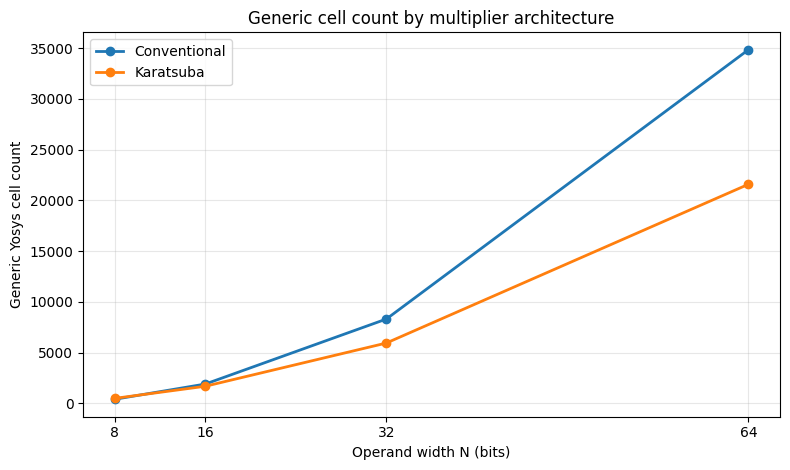

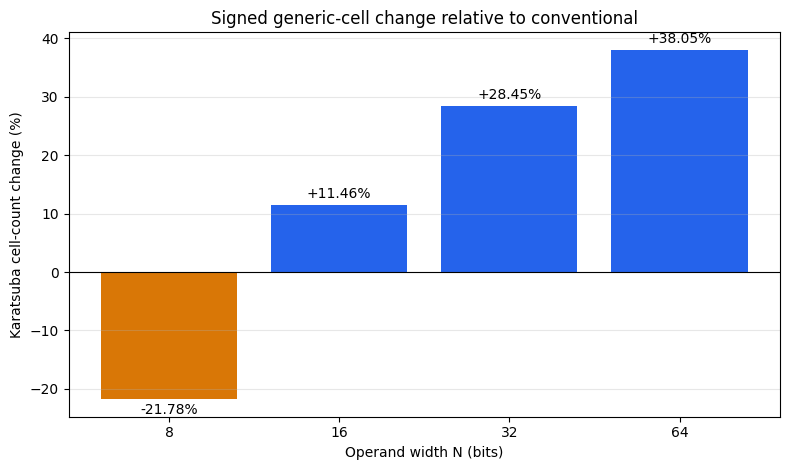

In [4]:
import matplotlib.pyplot as plt

widths = [r["width"] for r in rows]
conventional = [r["conventional"] for r in rows]
karatsuba = [r["karatsuba"] for r in rows]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(widths, conventional, marker="o", linewidth=2, label="Conventional")
ax.plot(widths, karatsuba, marker="o", linewidth=2, label="Karatsuba")
ax.set(xlabel="Operand width N (bits)", ylabel="Generic Yosys cell count",
       title="Generic cell count by multiplier architecture")
ax.set_xticks(widths)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

changes = [r["karatsuba_signed_reduction_pct"] for r in rows]
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = ["#d97706" if x < 0 else "#2563eb" for x in changes]
bars = ax.bar([str(n) for n in widths], changes, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.bar_label(bars, labels=[f"{x:+.2f}%" for x in changes], padding=3)
ax.set(xlabel="Operand width N (bits)", ylabel="Karatsuba cell-count change (%)",
       title="Signed generic-cell change relative to conventional")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


## Interpretation

At N=8, Karatsuba has 21.78% more generic cells than the conventional implementation, so the conventional design is the lower-count choice. At N=16, 32, and 64, Karatsuba has respectively 11.46%, 28.45%, and 38.05% fewer generic cells under the saved flow. This dataset therefore shows Karatsuba becoming the lower-count option by N=16; the observation applies only to these RTL versions, synthesis settings, and widths.

The separate `results/architecture_recommendations.csv` reports savings relative to whichever implementation has the higher count. That denominator means its N=8 recommendation reduction is 17.89%, whereas the signed Karatsuba change shown here is -21.78%. The notebook labels both definitions explicitly.


## sky130 standard-cell PPA

The repository also ships mapped results against the SkyWater `sky130_fd_sc_hd` high-density library (tt_025C_1v80 corner), produced by `scripts/run_sky130_ppa.py` with the ABC mapping script `scripts/abc_area.script` (`strash; map; topo`): explicit Yosys coarse synthesis, `dfflibmap`, ABC technology mapping, ABC `stime` static timing, then `stat -liberty`/`ltp` on the mapped netlist. This section cross-checks those CSVs and visualizes them; it does not rerun synthesis.

Three metrics are reported per architecture and width: mapped cell area (um^2), combinational critical-path delay from ABC static timing (ps, area-oriented mapping with no delay target), and static leakage (nW, liberty `cell_leakage_power` summed over mapped cells). Place-and-route and dynamic power are out of scope.

In [5]:
# Load and cross-check the sky130 mapped data.
sky = load_csv("sky130_baseline.csv")
sky_by = {}
for row in sky:
    sky_by[(int(row["width"]), row["architecture"])] = row

expected = {(w, a) for w in (8, 16, 32, 64)
            for a in ("conventional", "karatsuba_single", "karatsuba_recursive")}
assert set(sky_by) == expected, f"unexpected sky130 data coverage: {sorted(sky_by)}"

# Recompute the mapped area change versus conventional and compare with the
# checked-in comparison CSV.
recomputed = {}
for w in (8, 16, 32, 64):
    c = float(sky_by[(w, "conventional")]["sky130_area_um2"])
    for a in ("karatsuba_single", "karatsuba_recursive"):
        v = float(sky_by[(w, a)]["sky130_area_um2"])
        recomputed[(w, a)] = 100.0 * (v - c) / c
print("sky130 rows loaded:", len(sky))
print("recomputed mapped area change vs conventional (%):")
for (w, a), v in sorted(recomputed.items()):
    print(f"  N={w:>2} {a:<20} {v:+.2f}%")


sky130 rows loaded: 12
recomputed mapped area change vs conventional (%):
  N= 8 karatsuba_recursive  -5.57%
  N= 8 karatsuba_single     +39.99%
  N=16 karatsuba_recursive  -4.41%
  N=16 karatsuba_single     +2.47%
  N=32 karatsuba_recursive  -16.63%
  N=32 karatsuba_single     -10.66%
  N=64 karatsuba_recursive  -32.76%
  N=64 karatsuba_single     -20.56%


In [6]:
from IPython.display import display, Markdown

ARCH_LABEL = {
    "conventional": "Conventional",
    "karatsuba_single": "Karatsuba (single)",
    "karatsuba_recursive": "Karatsuba (recursive)",
}
WIDTHS = [8, 16, 32, 64]

def sky_table(metric, fmt, title):
    header = "| N | " + " | ".join(ARCH_LABEL[a] for a in ARCH_LABEL) + " |"
    lines = [title, header,
             "|---:|" + "---:|" * len(ARCH_LABEL)]
    for w in WIDTHS:
        lines.append(f"| {w} | " + " | ".join(
            fmt(float(sky_by[(w, a)][metric])) for a in ARCH_LABEL) + " |")
    display(Markdown("\n".join(lines)))

sky_table("sky130_area_um2", lambda v: f"{v:,.2f}", "**Mapped cell area (um^2)**")
sky_table("critical_path_delay_ps", lambda v: f"{v:,.0f}", "**Critical-path delay (ps, ABC stime)**")
sky_table("static_leakage_nw", lambda v: f"{v:.3f}", "**Static leakage (nW)**")


**Mapped cell area (um^2)**
| N | Conventional | Karatsuba (single) | Karatsuba (recursive) |
|---:|---:|---:|---:|
| 8 | 3,031.66 | 4,244.07 | 2,862.75 |
| 16 | 13,370.32 | 13,700.64 | 12,781.01 |
| 32 | 53,352.42 | 47,663.21 | 44,480.16 |
| 64 | 215,884.55 | 171,504.49 | 145,170.48 |

**Critical-path delay (ps, ABC stime)**
| N | Conventional | Karatsuba (single) | Karatsuba (recursive) |
|---:|---:|---:|---:|
| 8 | 2,703 | 4,612 | 3,629 |
| 16 | 3,877 | 6,713 | 6,871 |
| 32 | 5,450 | 9,231 | 12,208 |
| 64 | 7,026 | 14,993 | 18,011 |

**Static leakage (nW)**
| N | Conventional | Karatsuba (single) | Karatsuba (recursive) |
|---:|---:|---:|---:|
| 8 | 1.186 | 1.821 | 1.241 |
| 16 | 5.325 | 5.926 | 5.249 |
| 32 | 21.328 | 19.934 | 18.999 |
| 64 | 85.798 | 70.423 | 60.132 |

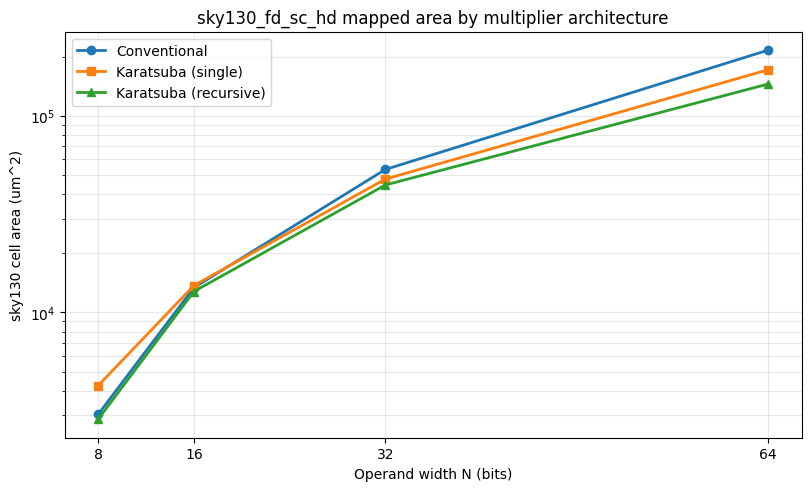

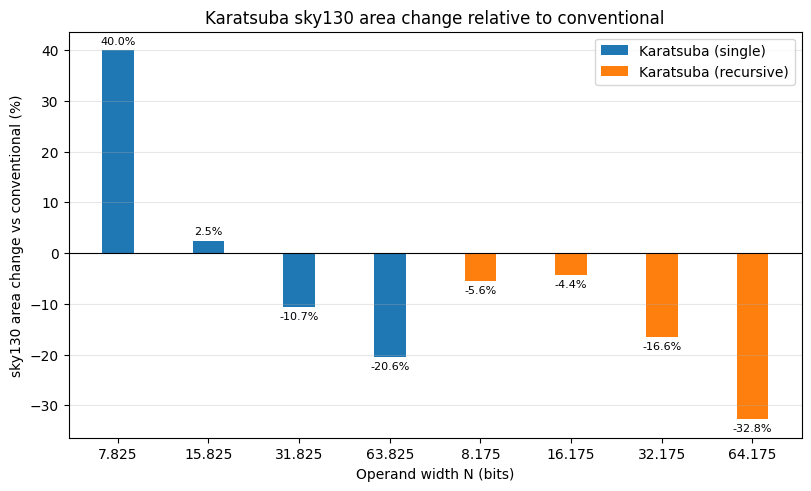

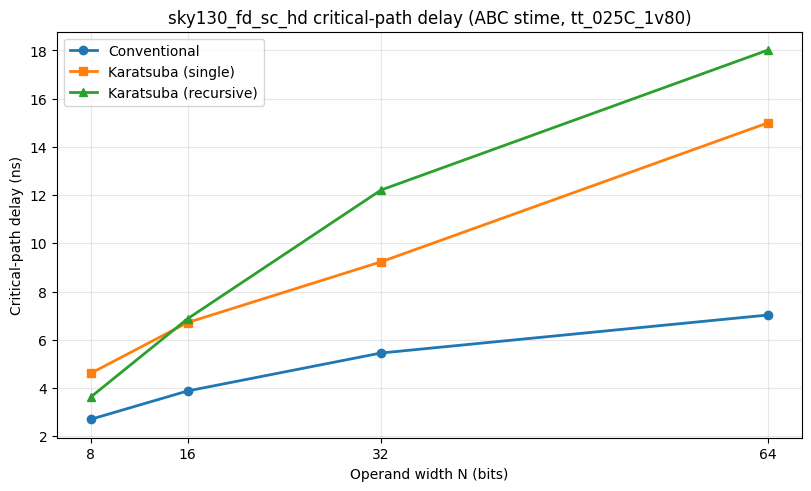

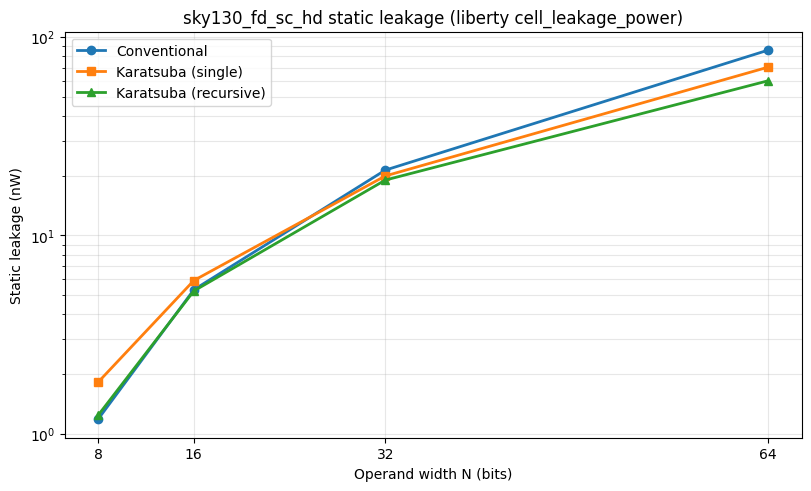

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for arch, style in [("conventional", "o"), ("karatsuba_single", "s"),
                    ("karatsuba_recursive", "^")]:
    xs = sorted(w for (w, a) in sky_by if a == arch)
    vals = [float(sky_by[(w, arch)]["sky130_area_um2"]) for w in xs]
    ax.plot(xs, vals, marker=style, linewidth=2, label=ARCH_LABEL[arch])
ax.set(xlabel="Operand width N (bits)", ylabel="sky130 cell area (um^2)",
       title="sky130_fd_sc_hd mapped area by multiplier architecture")
ax.set_yscale("log")
ax.set_xticks(WIDTHS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
bar_w = 0.35
for idx, arch in enumerate(("karatsuba_single", "karatsuba_recursive")):
    vals = [100.0 * (float(sky_by[(w, arch)]["sky130_area_um2"])
                     - float(sky_by[(w, "conventional")]["sky130_area_um2"]))
            / float(sky_by[(w, "conventional")]["sky130_area_um2"])
            for w in WIDTHS]
    xs = [w + (idx - 0.5) * bar_w for w in WIDTHS]
    bars = ax.bar([str(x) for x in xs], vals, width=bar_w,
                  label=ARCH_LABEL[arch])
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Operand width N (bits)",
       ylabel="sky130 area change vs conventional (%)",
       title="Karatsuba sky130 area change relative to conventional")
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for arch, style in [("conventional", "o"), ("karatsuba_single", "s"),
                    ("karatsuba_recursive", "^")]:
    xs = sorted(w for (w, a) in sky_by if a == arch)
    vals = [float(sky_by[(w, arch)]["critical_path_delay_ps"]) / 1000.0 for w in xs]
    ax.plot(xs, vals, marker=style, linewidth=2, label=ARCH_LABEL[arch])
ax.set(xlabel="Operand width N (bits)", ylabel="Critical-path delay (ns)",
       title="sky130_fd_sc_hd critical-path delay (ABC stime, tt_025C_1v80)")
ax.set_xticks(WIDTHS)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for arch, style in [("conventional", "o"), ("karatsuba_single", "s"),
                    ("karatsuba_recursive", "^")]:
    xs = sorted(w for (w, a) in sky_by if a == arch)
    vals = [float(sky_by[(w, arch)]["static_leakage_nw"]) for w in xs]
    ax.plot(xs, vals, marker=style, linewidth=2, label=ARCH_LABEL[arch])
ax.set(xlabel="Operand width N (bits)", ylabel="Static leakage (nW)",
       title="sky130_fd_sc_hd static leakage (liberty cell_leakage_power)")
ax.set_yscale("log")
ax.set_xticks(WIDTHS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()


### sky130 interpretation

Mapped area flips the generic-cell ranking: the recursive Karatsuba is the area winner at every measured width, from -5.6% at N=8 to -32.8% at N=64, and it also has the lowest static leakage at every width. The single-level variant pays a large mapped-area penalty at N=8 (+40.0%) before its savings appear at N>=32. Under the area-oriented mapping without a delay target, the conventional design stays the fastest at every width, so the Karatsuba variants trade speed for area in this flow. Note that at N=8 the recursive design reduces to the conventional base case by construction; the remaining ~6% area difference reflects ABC mapping sensitivity to the initial netlist structure.

## Simulation and formal evidence

The project records conventional simulation of 108 directed/pseudorandom vectors at each of N=8, 16, and 32, and Karatsuba simulation of 1,045 vectors at each of those widths. These are finite checks against multiplication; they are not proofs. The conventional testbench prints a status line rather than exiting nonzero on mismatch, so the output must be inspected.

The saved N=8 SymbiYosys run using Bitwuzla completed `PASS` (`rc=0`) for an assertion over the full 16-bit output. The N=16 full 32-bit output proof remains unresolved after timeout. A recorded N=16 bit-0 result passed, but it does not prove the remaining output bits. Timeout is neither proof nor counterexample. See the retained records `formal/logs/N8_sby_console_run2.log` and `formal/logs/N8_sby_status_run2.txt`. The recursive design is additionally verified against a bit-accurate software model: exhaustive for all N<=8 input pairs and 150,000+ directed/pseudorandom vectors at each of N=16, 32, 64 (`formal/logs/recursive_model_verify.log`).

No N=16 proof is run by this notebook.


## Reproduction

Run the notebook from a checkout root or from the notebook's directory. It locates the nearest parent containing both `results/comparison.csv` and the multiplier RTL. The core data and plots require Python 3.12, Jupyter/IPython, and Matplotlib; the rest of the analysis uses Python's standard library.

The following PowerShell commands reproduce the recorded checks. Run synthesis in a disposable copy because the existing scripts overwrite result CSVs, logs, plots, and summary files.

```powershell
# From the project root; uses the currently installed OSS CAD Suite.
$suite = 'C:\path\to\oss-cad-suite' # replace with your local suite path
$env:PATH = "$suite\bin;$suite\lib;$env:PATH"

# Simulation (outputs are directed to a temp directory; run VVP there).
$sim = Join-Path $env:TEMP 'autoaccel-sim'
New-Item -ItemType Directory -Force $sim | Out-Null
iverilog -g2012 -s tb_conventional_multiplier -o (Join-Path $sim 'conventional.vvp') rtl/multiplier/conventional_multiplier.sv tb/tb_conventional_multiplier.sv
Push-Location $sim; vvp .\conventional.vvp; Pop-Location
iverilog -g2012 -s karatsuba_multiplier_tb_top -o (Join-Path $sim 'karatsuba.vvp') rtl/multiplier/PARAMETERIZED_MULTIPLIER.sv tb/tb_PARAMETERIZED_KARATSUBA.sv
Push-Location $sim; vvp .\karatsuba.vvp; Pop-Location

# Synthesis and table/plot generation. Use a disposable checkout/copy.
python scripts/run_autoaccel.py

# Recorded N=8 formal check (not required to execute this analysis notebook).
Push-Location formal
sby.exe -d work/SBY_N8_reproduction multiplier_N8_sby.sby
Pop-Location
```

The N=8 formal console transcript and status record are retained under `formal/logs/`. The full synthesis workflow is not safe to run over audited baseline data unless working in a copy.


## Conclusion

For the saved generic-cell metric, conventional multiplication is smaller at N=8; Karatsuba is smaller at N=16, 32, and 64. Under sky130 standard-cell mapping, the recursive Karatsuba is the area and leakage winner at every measured width (up to -32.8% area at N=64), while the conventional design remains the fastest under the area-oriented mapping. The N=8 implementations are proven equivalent over the full output. N=16 full-output equivalence has not been established. These conclusions are limited to the saved synthesis flows and formal evidence.
